# Data Preprocessing & Feature Engineering — SOLUTIONS
## Topic: Missing Values, Outliers & Encoding

This is the completed version of the practice notebook. Each question is
followed by a worked answer and a short explanation. Use it to teach from,
or to check your own work after attempting the practice notebook.

## Step 0 — Setup & the messy dataset *(provided — just run this cell)*

We work with a small employee dataset (20 rows) that was deliberately built
to contain every problem we study: missing values, an impossible age (150),
a huge salary outlier (9,999,999), an ordinal column (Education) and several
nominal columns (Gender, Department, City).

In [1]:
import pandas as pd
import numpy as np

data = {
    'EmployeeID': list(range(1, 21)),
    'Age':        [25,30,np.nan,35,28,150,40,33,29,45,38,26,50,31,27,np.nan,42,36,34,39],
    'Gender':     ['Male','Female','Male','Female','Male','Female',np.nan,'Male','Female','Male',
                   'Female','Male','Female','Male','Female','Male','Female','Male','Female','Male'],
    'Department': ['Sales','IT','HR','Finance','IT','Sales','HR','Finance','IT','Sales',
                   np.nan,'IT','Finance','HR','Sales','IT','Finance','Sales','HR','IT'],
    'Education':  ['Bachelor','Master','Bachelor','PhD','Bachelor','High School','Master','Bachelor',
                   'Master','High School','PhD','Bachelor','Master','Bachelor','High School','Master',
                   'PhD','Bachelor','Master','Bachelor'],
    'Experience': [2,5,3,10,4,1,12,8,5,np.nan,15,3,20,np.nan,2,7,18,9,11,np.nan],
    'Salary':     [45000,60000,50000,90000,np.nan,35000,75000,65000,58000,48000,
                   95000,9999999,110000,np.nan,38000,70000,105000,62000,72000,68000],
    'City':       ['Mumbai','Delhi','Mumbai','Bangalore','Delhi','Pune','Mumbai','Bangalore','Delhi',
                   'Pune','Mumbai','Delhi','Bangalore','Pune','Mumbai','Delhi','Bangalore','Pune',
                   'Mumbai','Delhi'],
}
df = pd.DataFrame(data)
print("Shape:", df.shape)
df.head()

Shape: (20, 8)


,EmployeeID,Age,Gender,Department,Education,Experience,Salary,City
0,1,25.0,Male,Sales,Bachelor,2.0,45000.0,Mumbai
1,2,30.0,Female,IT,Master,5.0,60000.0,Delhi
2,3,NaN,Male,HR,Bachelor,3.0,50000.0,Mumbai
3,4,35.0,Female,Finance,PhD,10.0,90000.0,Bangalore
4,5,28.0,Male,IT,Bachelor,4.0,NaN,Delhi


# Part 1 — Handling Missing Values

### Q1. Inspect the data
Display the first 5 rows, then use `.info()` to see the column types and how many non-null values each column has.

In [2]:
display(df.head())
df.info()

,EmployeeID,Age,Gender,Department,Education,Experience,Salary,City
0,1,25.0,Male,Sales,Bachelor,2.0,45000.0,Mumbai
1,2,30.0,Female,IT,Master,5.0,60000.0,Delhi
2,3,NaN,Male,HR,Bachelor,3.0,50000.0,Mumbai
3,4,35.0,Female,Finance,PhD,10.0,90000.0,Bangalore
4,5,28.0,Male,IT,Bachelor,4.0,NaN,Delhi


<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   EmployeeID  20 non-null     int64  
 1   Age         18 non-null     float64
 2   Gender      19 non-null     str    
 3   Department  19 non-null     str    
 4   Education   20 non-null     str    
 5   Experience  17 non-null     float64
 6   Salary      18 non-null     float64
 7   City        20 non-null     str    
dtypes: float64(3), int64(1), str(4)
memory usage: 1.4 KB


> **Explanation:** `.info()` shows the dtype and non-null count of every column — a quick way to spot which columns have missing data.

### Q2. Count missing values
Count how many values are missing in **each** column.

In [3]:
df.isnull().sum()

EmployeeID    0
Age           2
Gender        1
Department    1
Education     0
Experience    3
Salary        2
City          0
dtype: int64

> **Explanation:** `isnull()` returns True/False; summing the True values gives the count per column.

### Q3. Percentage missing
Show the **percentage** of values missing in each column, rounded to 1 decimal place.

In [4]:
(df.isnull().mean() * 100).round(1)

EmployeeID     0.0
Age           10.0
Gender         5.0
Department     5.0
Education      0.0
Experience    15.0
Salary        10.0
City           0.0
dtype: float64

> **Explanation:** Percentages are easier to judge than raw counts. Here Experience (15%) is the worst, but all are well under 50%, so we will fill them rather than drop.

### Q4. Which column has the most missing values?
Answer in the markdown cell, then prove it with one line of code.

In [5]:
df.isnull().sum().idxmax()

'Experience'

> **Explanation:** **Answer:** `Experience` has the most missing values (3 of them, = 15%).

### Q5. Impute `Age` with the median
Fill the missing ages with the column **median** (median is safer than mean because Age has the outlier 150).

In [6]:
df['Age'] = df['Age'].fillna(df['Age'].median())
print('Age median used:', df['Age'].median())

Age median used: 34.5


> **Explanation:** Median = 34.5. We use median (not mean) because the value 150 would inflate the mean.

### Q6. Impute `Experience` with the median

In [7]:
df['Experience'] = df['Experience'].fillna(df['Experience'].median())
print('Experience median used:', df['Experience'].median())

Experience median used: 7.0


> **Explanation:** Median experience = 7.0.

### Q7. Impute `Salary` with the median

In [8]:
df['Salary'] = df['Salary'].fillna(df['Salary'].median())
print('Salary median used:', df['Salary'].median())

Salary median used: 66500.0


> **Explanation:** Median salary = 66,500. Using the mean here would give ~560,000 because of the 9,999,999 outlier — clearly unrealistic.

### Q8. Impute `Gender` with the mode
`Gender` is categorical (text), so fill it with the **most frequent** value.

In [9]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
print('Gender mode used:', df['Gender'].mode()[0])

Gender mode used: Male


> **Explanation:** Mode = 'Male'. The mode is the right choice for categorical columns (mean/median make no sense for text).

### Q9. Impute `Department` with the mode

In [10]:
df['Department'] = df['Department'].fillna(df['Department'].mode()[0])
print('Department mode used:', df['Department'].mode()[0])

Department mode used: IT


> **Explanation:** Mode = 'IT'.

### Q10. Verify no missing values remain
Confirm the total number of missing values across the whole DataFrame is now **0**.

In [11]:
df.isnull().sum().sum()

np.int64(0)

> **Explanation:** Should return 0 — the dataset is now complete.

# Part 2 — Detecting & Removing Outliers (IQR)

### Q11. Quartiles & IQR for `Age`
Compute `Q1` (25th percentile), `Q3` (75th percentile) and `IQR = Q3 - Q1` for the `Age` column. Print all three.

In [12]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1
print('Q1 =', Q1, ' Q3 =', Q3, ' IQR =', IQR)

Q1 = 29.75  Q3 = 39.25  IQR = 9.5


> **Explanation:** Q1 = 29.75, Q3 = 39.25, IQR = 9.5.

### Q12. Lower & upper bounds for `Age`
Using the IQR rule, compute the lower and upper 'fences':

$$\text{lower}=Q1-1.5\times IQR \qquad \text{upper}=Q3+1.5\times IQR$$

In [13]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print('Age bounds:', lower, 'to', upper)

Age bounds: 15.5 to 53.5


> **Explanation:** Bounds are 15.5 to 53.5. Any age outside this range is an outlier.

### Q13. Find the outlier rows in `Age`
Show the rows where `Age` is below the lower bound or above the upper bound.

In [14]:
df[(df['Age'] < lower) | (df['Age'] > upper)]

,EmployeeID,Age,Gender,Department,Education,Experience,Salary,City
5,6,150.0,Female,Sales,High School,1.0,35000.0,Pune


> **Explanation:** Only EmployeeID 6 (Age = 150) is flagged.

### Q14. Repeat for `Salary`
Compute Q1, Q3, IQR, the bounds, and show the outlier rows for the `Salary` column.

In [15]:
Q1s = df['Salary'].quantile(0.25)
Q3s = df['Salary'].quantile(0.75)
IQRs = Q3s - Q1s
low_s = Q1s - 1.5 * IQRs
high_s = Q3s + 1.5 * IQRs
print('Salary bounds:', low_s, 'to', high_s)
df[(df['Salary'] < low_s) | (df['Salary'] > high_s)]

Salary bounds: 21875.0 to 112875.0


,EmployeeID,Age,Gender,Department,Education,Experience,Salary,City
11,12,26.0,Male,IT,Bachelor,3.0,9999999.0,Delhi


> **Explanation:** Bounds are 21,875 to 112,875. EmployeeID 12 (Salary = 9,999,999) is the outlier.

### Q15. Remove the outliers
Keep only the rows where **both** `Age` and `Salary` fall inside their IQR bounds. Print the shape before and after.

In [16]:
print('Before:', df.shape)
mask = pd.Series(True, index=df.index)
for col in ['Age', 'Salary']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    mask &= df[col].between(q1 - 1.5*iqr, q3 + 1.5*iqr)
df = df[mask].reset_index(drop=True)
print('After: ', df.shape)

Before: (20, 8)
After:  (18, 8)


> **Explanation:** Two rows are removed (the 150 age and the 9,999,999 salary). Shape goes from (20, 8) to (18, 8).

### Q16. *(Optional)* Visualise with a box plot
Draw a box plot of `Age` to see that the extreme value is gone. (Requires `matplotlib`.)

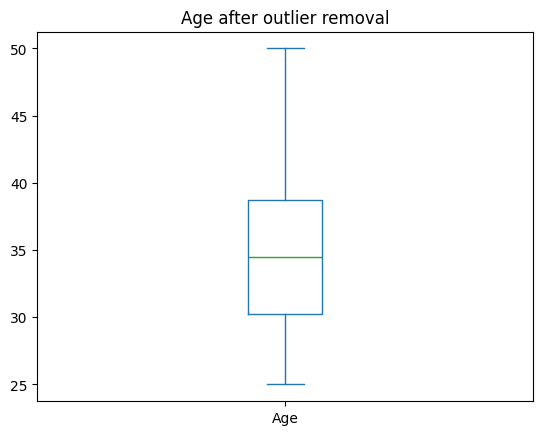

In [17]:
import matplotlib.pyplot as plt
df['Age'].plot(kind='box', title='Age after outlier removal')
plt.show()

> **Explanation:** The box plot now shows a tidy distribution with no points far beyond the whiskers.

# Part 3 — Encoding Categorical Variables

### Q17. Label-encode `Education` (ordinal)
`Education` has a natural order: High School < Bachelor < Master < PhD. Create a new column `Education_Label` mapping these to 0, 1, 2, 3.

In [18]:
edu_order = {'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3}
df['Education_Label'] = df['Education'].map(edu_order)
df[['Education', 'Education_Label']].head()

,Education,Education_Label
0,Bachelor,1
1,Master,2
2,Bachelor,1
3,PhD,3
4,Bachelor,1


> **Explanation:** Because Education is **ordinal**, label encoding is correct — the numbers preserve the real order.

### Q18. Encode `Gender` as 0/1
`Gender` has only two values, so map Male -> 0 and Female -> 1 into a new column `Gender_Label`.

In [19]:
df['Gender_Label'] = df['Gender'].map({'Male': 0, 'Female': 1})
df[['Gender', 'Gender_Label']].head()

,Gender,Gender_Label
0,Male,0
1,Female,1
2,Male,0
3,Female,1
4,Male,0


> **Explanation:** For a two-value column a single 0/1 column is enough.

### Q19. One-hot encode `Department` and `City`
These are **nominal** (no order), so use one-hot encoding. Use `pd.get_dummies` with prefixes `Dept` and `City`.

In [20]:
df = pd.get_dummies(df, columns=['Department', 'City'], prefix=['Dept', 'City'])
# convert True/False dummy columns to 1/0 integers
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)
df.head()

,EmployeeID,Age,Gender,Education,Experience,Salary,Education_Label,Gender_Label,Dept_Finance,Dept_HR,Dept_IT,Dept_Sales,City_Bangalore,City_Delhi,City_Mumbai,City_Pune
0,1,25.0,Male,Bachelor,2.0,45000.0,1,0,0,0,0,1,0,0,1,0
1,2,30.0,Female,Master,5.0,60000.0,2,1,0,0,1,0,0,1,0,0
2,3,34.5,Male,Bachelor,3.0,50000.0,1,0,0,1,0,0,0,0,1,0
3,4,35.0,Female,PhD,10.0,90000.0,3,1,1,0,0,0,1,0,0,0
4,5,28.0,Male,Bachelor,4.0,66500.0,1,0,0,0,1,0,0,1,0,0


> **Explanation:** One-hot avoids inventing a fake order between cities or departments. Each category becomes its own 0/1 column.

### Q20. Inspect the final dataset
Print the final shape and the list of columns. Confirm there are no missing values.

In [21]:
print('Final shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Columns:')
print(list(df.columns))
df.head()

Final shape: (18, 16)
Missing values: 0
Columns:
['EmployeeID', 'Age', 'Gender', 'Education', 'Experience', 'Salary', 'Education_Label', 'Gender_Label', 'Dept_Finance', 'Dept_HR', 'Dept_IT', 'Dept_Sales', 'City_Bangalore', 'City_Delhi', 'City_Mumbai', 'City_Pune']


,EmployeeID,Age,Gender,Education,Experience,Salary,Education_Label,Gender_Label,Dept_Finance,Dept_HR,Dept_IT,Dept_Sales,City_Bangalore,City_Delhi,City_Mumbai,City_Pune
0,1,25.0,Male,Bachelor,2.0,45000.0,1,0,0,0,0,1,0,0,1,0
1,2,30.0,Female,Master,5.0,60000.0,2,1,0,0,1,0,0,1,0,0
2,3,34.5,Male,Bachelor,3.0,50000.0,1,0,0,1,0,0,0,0,1,0
3,4,35.0,Female,PhD,10.0,90000.0,3,1,1,0,0,0,1,0,0,0
4,5,28.0,Male,Bachelor,4.0,66500.0,1,0,0,0,1,0,0,1,0,0


> **Explanation:** Final dataset: 18 rows x 16 columns, fully numeric, no missing values — ready for a model.

# Bonus Challenge

### Q21. Write a single `preprocess(df)` function
Combine everything into one reusable function that takes a raw DataFrame and returns the cleaned, encoded version. Test it by re-creating the raw data and passing it in.

In [22]:
def preprocess(raw):
    d = raw.copy()
    # 1. impute
    for col in ['Age', 'Experience', 'Salary']:
        d[col] = d[col].fillna(d[col].median())
    for col in ['Gender', 'Department']:
        d[col] = d[col].fillna(d[col].mode()[0])
    # 2. remove outliers (IQR)
    mask = pd.Series(True, index=d.index)
    for col in ['Age', 'Salary']:
        q1, q3 = d[col].quantile(0.25), d[col].quantile(0.75)
        iqr = q3 - q1
        mask &= d[col].between(q1 - 1.5*iqr, q3 + 1.5*iqr)
    d = d[mask].reset_index(drop=True)
    # 3. encode
    d['Education_Label'] = d['Education'].map(
        {'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3})
    d['Gender_Label'] = d['Gender'].map({'Male': 0, 'Female': 1})
    d = pd.get_dummies(d, columns=['Department', 'City'], prefix=['Dept', 'City'])
    bool_cols = d.select_dtypes(include='bool').columns
    d[bool_cols] = d[bool_cols].astype(int)
    return d

raw = pd.DataFrame(data)        # fresh copy of the original messy data
clean = preprocess(raw)
print('Cleaned shape:', clean.shape)
clean.head()

Cleaned shape: (18, 16)


,EmployeeID,Age,Gender,Education,Experience,Salary,Education_Label,Gender_Label,Dept_Finance,Dept_HR,Dept_IT,Dept_Sales,City_Bangalore,City_Delhi,City_Mumbai,City_Pune
0,1,25.0,Male,Bachelor,2.0,45000.0,1,0,0,0,0,1,0,0,1,0
1,2,30.0,Female,Master,5.0,60000.0,2,1,0,0,1,0,0,1,0,0
2,3,34.5,Male,Bachelor,3.0,50000.0,1,0,0,1,0,0,0,0,1,0
3,4,35.0,Female,PhD,10.0,90000.0,3,1,1,0,0,0,1,0,0,0
4,5,28.0,Male,Bachelor,4.0,66500.0,1,0,0,0,1,0,0,1,0,0


> **Explanation:** A single function like this is exactly what you would reuse in a real project (and later wrap inside a scikit-learn Pipeline).

---
*End of solutions. The final cleaned dataset has 18 rows and 16 columns.*